In [10]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
iris_df = iris.frame
Xc = iris_df.drop(columns=["target"])
yc = iris.target
print(Xc.head())
print(iris.target_names)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
['setosa' 'versicolor' 'virginica']


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split  # Added missing import
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Ensure Xc (features) and yc (target) are already loaded/defined before this step
Xtr, Xte, ytr, yte = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

log_model.fit(Xtr, ytr)
pred_log = log_model.predict(Xte)
print(pred_log[:10])

[0 2 1 1 0 1 0 0 2 1]


In [7]:
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
knn.fit(Xtr, ytr)
pred_knn = knn.predict(Xte)
print(pred_knn[:10])

[0 2 1 1 0 1 0 0 2 1]


In [8]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(Xtr, ytr)
pred_nb = nb.predict(Xte)
print(pred_nb[:10])

[0 2 1 1 0 1 0 0 2 1]


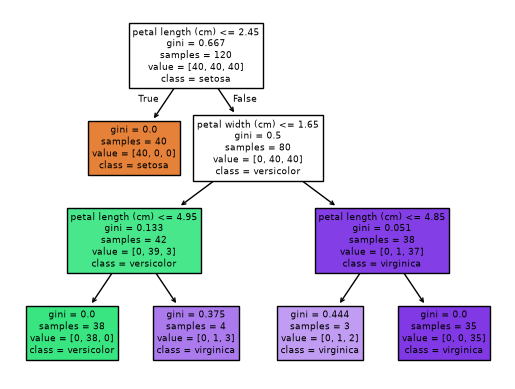

In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = DecisionTreeClassifier(
    max_depth=3, random_state=42
)
tree.fit(Xtr, ytr)
pred_tree = tree.predict(Xte)
plot_tree(tree, feature_names=Xc.columns,
          class_names=iris.target_names,
          filled=True)
plt.show()

In [12]:
from sklearn.svm import SVC
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)
svm.fit(Xtr, ytr)
pred_svm = svm.predict(Xte)
print(pred_svm[:10])

[0 2 1 1 0 1 0 0 2 1]


In [13]:
from sklearn.metrics import accuracy_score
print("Classes:", iris.target_names)
print("Logistic accuracy:",
      accuracy_score(yte, pred_log))
print("Tree accuracy:",
      accuracy_score(yte, pred_tree))

Classes: ['setosa' 'versicolor' 'virginica']
Logistic accuracy: 0.9333333333333333
Tree accuracy: 0.9666666666666667


In [14]:
from sklearn.linear_model import LogisticRegression
weighted = LogisticRegression(
    class_weight="balanced",
    max_iter=2000
)
print("Balanced class weights enabled")

Balanced class weights enabled


In [18]:
from imblearn.over_sampling import SMOTE
import pandas as pd

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(Xtr, ytr)

print("Before:\n", pd.Series(ytr).value_counts())
print("\nAfter:\n", pd.Series(y_res).value_counts())

Before:
 target
0    40
2    40
1    40
Name: count, dtype: int64

After:
 target
0    40
2    40
1    40
Name: count, dtype: int64


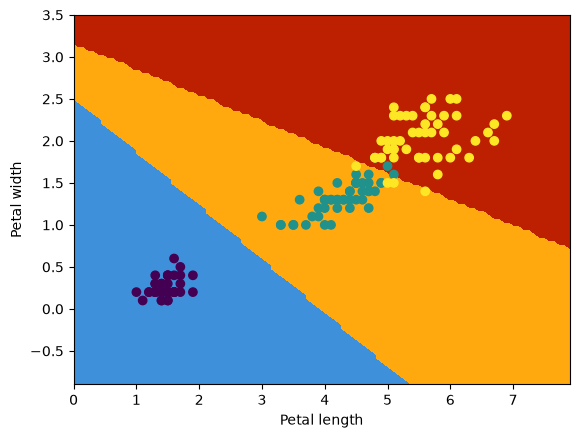

In [19]:
from sklearn.inspection import DecisionBoundaryDisplay
X2 = Xc[["petal length (cm)",
         "petal width (cm)"]]
boundary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
boundary_model.fit(X2, yc)
DecisionBoundaryDisplay.from_estimator(
    boundary_model, X2,
    response_method="predict",
    plot_method="contourf"
)
plt.scatter(X2.iloc[:,0], X2.iloc[:,1], c=yc)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.show()

In [20]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
print("Accuracy:", accuracy_score(yte,pred_log))
print("Precision:", precision_score(
    yte,pred_log,average="weighted"))
print("Recall:", recall_score(
    yte,pred_log,average="weighted"))
print("F1:", f1_score(
    yte,pred_log,average="weighted"))

Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1: 0.9333333333333333


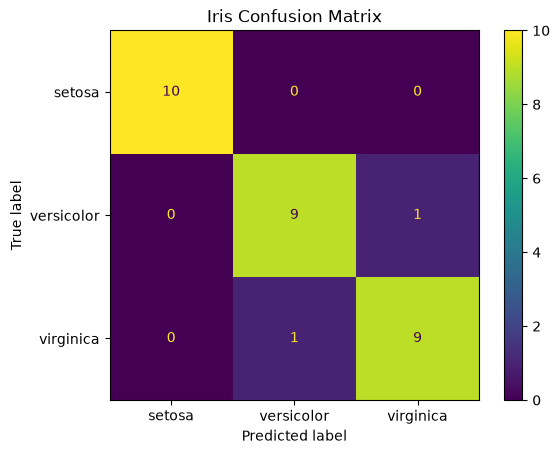

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    yte, pred_log,
    display_labels=iris.target_names
)
plt.title("Iris Confusion Matrix")
plt.show()

ROC-AUC: 0.9239


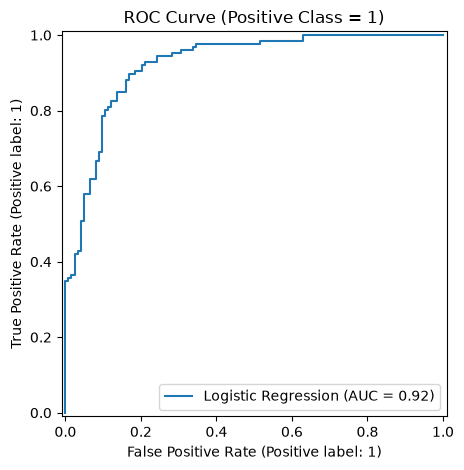

In [30]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split
X, y_binary = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    random_state=42,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.25, stratify=y_binary, random_state=42
)

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
probabilities = model.predict_proba(X_test)[:, 1]

# 4. Compute ROC-AUC and plot the ROC curve
auc = roc_auc_score(y_test, probabilities)
print(f"ROC-AUC: {auc:.4f}")

disp = RocCurveDisplay.from_predictions(
    y_test,
    probabilities,
    name="Logistic Regression",
)
disp.ax_.set_title("ROC Curve (Positive Class = 1)")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import accuracy_score, f1_score
models = {
 "Logistic": log_model,
 "KNN": knn,
 "Naive Bayes": nb,
 "Decision Tree": tree,
 "SVM": svm
}
for name, model in models.items():
    pred = model.predict(Xte)
    print(name,
          "Accuracy:", round(accuracy_score(yte,pred),3),
          "F1:", round(f1_score(yte,pred,average="weighted"),3))

Logistic Accuracy: 0.933 F1: 0.933
KNN Accuracy: 0.933 F1: 0.933
Naive Bayes Accuracy: 0.967 F1: 0.967
Decision Tree Accuracy: 0.967 F1: 0.967
SVM Accuracy: 0.967 F1: 0.967


In [24]:
import joblib
joblib.dump(log_model, "iris_classifier.joblib")
loaded_model = joblib.load("iris_classifier.joblib")
print(loaded_model.predict(Xte.iloc[[0]]))

[0]


In [25]:
# Student tasks
# 1. Change regression feature(s).
# 2. Compare Linear, Polynomial and Ridge.
# 3. Report MAE, RMSE and R2.
# 4. Train 5 classifiers on Iris.
# 5. Report accuracy and weighted F1.
# 6. Draw a confusion matrix.
# 7. Explain one prediction.